# CO2 Emissions (Canada) — Regression pipeline: OLS (manual + statsmodels), regularization (Ridge/Lasso), with statistical diagnostics.**Target:** `CO2 Emissions(g/km)`

## 1. Load, Initial Clean & Feature Drops

In [ ]:
# Core imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

RANDOM_STATE = 42

In [ ]:
# Load dataset
df = pd.read_csv('/content/CO2_Emissions_Canada.csv')

# Strip whitespace from column names
df.columns = df.columns.str.strip()

print(df.shape)
print(df.columns.tolist())

# Handle missing values by dropping the six appended incomplete rows
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape after dropping rows with missing values:", df.shape)

(7391, 12)
['Make', 'Model', 'Vehicle Class', 'Engine Size(L)', 'Cylinders', 'Transmission', 'Fuel Type', 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)', 'CO2 Emissions(g/km)']
Shape after dropping rows with missing values: (7385, 12)


In [ ]:
df.head()

,Make,Model,Vehicle Class,Engine Size(L),Cylinders,Transmission,Fuel Type,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),CO2 Emissions(g/km)
0,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7385 entries, 0 to 7384
Data columns (total 12 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Make                              7385 non-null   object 
 1   Model                             7385 non-null   object 
 2   Vehicle Class                     7385 non-null   object 
 3   Engine Size(L)                    7385 non-null   float64
 4   Cylinders                         7385 non-null   int64  
 5   Transmission                      7385 non-null   object 
 6   Fuel Type                         7385 non-null   object 
 7   Fuel Consumption City (L/100 km)  7385 non-null   float64
 8   Fuel Consumption Hwy (L/100 km)   7385 non-null   float64
 9   Fuel Consumption Comb (L/100 km)  7385 non-null   float64
 10  Fuel Consumption Comb (mpg)       7385 non-null   int64  
 11  CO2 Emissions(g/km)               7385 non-null   int64  
dtypes: flo

In [ ]:
# Drop high-cardinality identifier columns
df.drop(columns=['Make', 'Model'], inplace=True)
print("Shape after dropping Make/Model:", df.shape)

Shape after dropping Make/Model: (7385, 10)


In [ ]:
# Drop duplicate rows
dup_count = df.duplicated().sum()
print("Duplicate rows found:", dup_count)
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
print("Shape after dropping duplicates:", df.shape)

Duplicate rows found: 2453
Shape after dropping duplicates: (4932, 10)


In [ ]:
# Missing value audit
print(df.isnull().sum())

Vehicle Class                       0
Engine Size(L)                      0
Cylinders                           0
Transmission                        0
Fuel Type                           0
Fuel Consumption City (L/100 km)    0
Fuel Consumption Hwy (L/100 km)     0
Fuel Consumption Comb (L/100 km)    0
Fuel Consumption Comb (mpg)         0
CO2 Emissions(g/km)                 0
dtype: int64


In [ ]:
TARGET = 'CO2 Emissions(g/km)'

# Drop rows with missing target
df.dropna(subset=[TARGET], inplace=True)

num_cols = ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)',
            'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
            'Fuel Consumption Comb (mpg)']
cat_cols = ['Vehicle Class', 'Transmission', 'Fuel Type']

# Impute numerical predictors with median
for c in num_cols:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].median())

# Impute categorical predictors with mode
for c in cat_cols:
    if df[c].isnull().sum() > 0:
        df[c] = df[c].fillna(df[c].mode()[0])

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


## 2. Domain-Based Category Consolidation & Label Encoding

In [ ]:
print(df['Transmission'].unique())

['AS5' 'M6' 'AV7' 'AS6' 'AM6' 'A6' 'AM7' 'AV8' 'AS8' 'A7' 'A8' 'M7' 'A4'
 'M5' 'AV' 'A5' 'AS7' 'A9' 'AS9' 'AV6' 'AS4' 'AM5' 'AM8' 'AM9' 'AS10'
 'A10' 'AV10']


In [ ]:
def consolidate_transmission(t):
    t = str(t).strip()
    if t.startswith('AM') or t.startswith('AS'):
        return 'Automated_Manual'
    if t.startswith('AV') or t.startswith('CVT'):
        return 'CVT'
    if t.startswith('A') and len(t) > 1 and t[1:].isdigit():
        return 'Automatic'
    if t.startswith('M'):
        return 'Manual'
    return 'Other'

df['Transmission_Grouped'] = df['Transmission'].apply(consolidate_transmission)
df['Transmission_Grouped'].value_counts()

,count
Transmission_Grouped,
Automated_Manual,2686
Automatic,1032
Manual,797
CVT,417


In [ ]:
print(df['Vehicle Class'].unique())

['COMPACT' 'SUV - SMALL' 'MID-SIZE' 'TWO-SEATER' 'MINICOMPACT'
 'SUBCOMPACT' 'FULL-SIZE' 'STATION WAGON - SMALL' 'SUV - STANDARD'
 'VAN - CARGO' 'VAN - PASSENGER' 'PICKUP TRUCK - STANDARD' 'MINIVAN'
 'SPECIAL PURPOSE VEHICLE' 'STATION WAGON - MID-SIZE'
 'PICKUP TRUCK - SMALL']


In [ ]:
vehicle_class_map = {
    'SUBCOMPACT': 'Compact/Sedan', 'COMPACT': 'Compact/Sedan', 'MID-SIZE': 'Compact/Sedan',
    'FULL-SIZE': 'Compact/Sedan', 'TWO-SEATER': 'Compact/Sedan', 'MINICOMPACT': 'Compact/Sedan',
    'SUV - SMALL': 'SUV', 'SUV - STANDARD': 'SUV',
    'PICKUP TRUCK - SMALL': 'Truck', 'PICKUP TRUCK - STANDARD': 'Truck',
    'VAN - PASSENGER': 'Van', 'VAN - CARGO': 'Van', 'MINIVAN': 'Van',
    'STATION WAGON - SMALL': 'Station Wagon', 'STATION WAGON - MID-SIZE': 'Station Wagon',
    'SPECIAL PURPOSE VEHICLE': 'Special'
}

df['Vehicle_Class_Grouped'] = (
    df['Vehicle Class'].str.strip().str.upper().map(vehicle_class_map)
)
df['Vehicle_Class_Grouped'] = df['Vehicle_Class_Grouped'].fillna('Special')
df['Vehicle_Class_Grouped'].value_counts()

,count
Vehicle_Class_Grouped,
Compact/Sedan,2851
SUV,1242
Truck,447
Station Wagon,239
Van,106
Special,47


In [ ]:
from sklearn.preprocessing import LabelEncoder

le_vehicle = LabelEncoder()
le_transmission = LabelEncoder()
le_fuel = LabelEncoder()

df['Vehicle_Class_Enc'] = le_vehicle.fit_transform(df['Vehicle_Class_Grouped'])
df['Transmission_Enc'] = le_transmission.fit_transform(df['Transmission_Grouped'])
df['Fuel_Type_Enc'] = le_fuel.fit_transform(df['Fuel Type'])

print("Vehicle Class mapping:", dict(zip(le_vehicle.classes_, le_vehicle.transform(le_vehicle.classes_))))
print("Transmission mapping:", dict(zip(le_transmission.classes_, le_transmission.transform(le_transmission.classes_))))
print("Fuel Type mapping:", dict(zip(le_fuel.classes_, le_fuel.transform(le_fuel.classes_))))

Vehicle Class mapping: {'Compact/Sedan': np.int64(0), 'SUV': np.int64(1), 'Special': np.int64(2), 'Station Wagon': np.int64(3), 'Truck': np.int64(4), 'Van': np.int64(5)}
Transmission mapping: {'Automated_Manual': np.int64(0), 'Automatic': np.int64(1), 'CVT': np.int64(2), 'Manual': np.int64(3)}
Fuel Type mapping: {'D': np.int64(0), 'E': np.int64(1), 'N': np.int64(2), 'X': np.int64(3), 'Z': np.int64(4)}


## 3. Exploratory Data Analysis (EDA)

### 3.1 Target Variable

In [ ]:
df[TARGET].describe()

,CO2 Emissions(g/km)
count,4932.000000
mean,247.239051
std,58.837217
min,96.000000
25%,204.000000
50%,241.000000
75%,283.000000
max,522.000000


In [ ]:
q1, q3 = df[TARGET].quantile([0.25, 0.75])
iqr = q3 - q1
print(f"IQR: {iqr:.2f}  (Q1={q1:.2f}, Q3={q3:.2f})")

IQR: 79.00  (Q1=204.00, Q3=283.00)


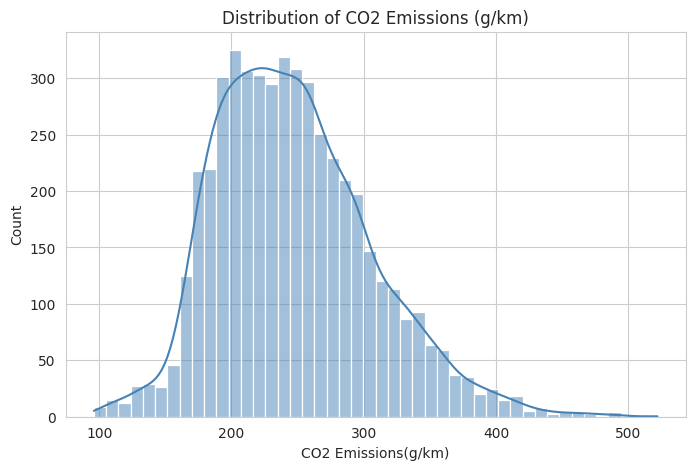

In [ ]:
fig, ax = plt.subplots()
sns.histplot(df[TARGET], kde=True, ax=ax, color='steelblue')
ax.set_title('Distribution of CO2 Emissions (g/km)')
plt.show()

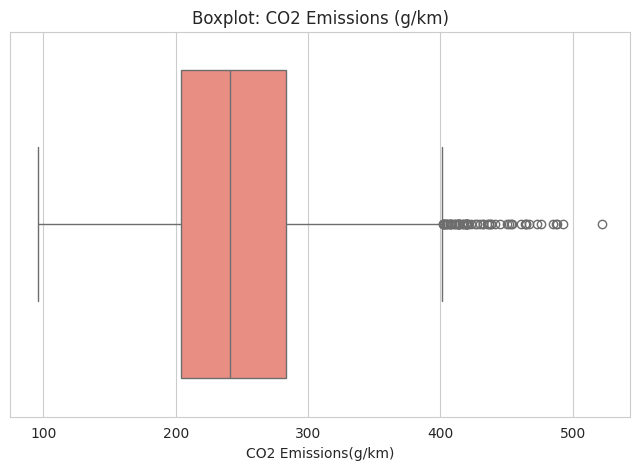

In [ ]:
fig, ax = plt.subplots()
sns.boxplot(x=df[TARGET], ax=ax, color='salmon')
ax.set_title('Boxplot: CO2 Emissions (g/km)')
plt.show()

### 3.2 Numerical Predictors

In [ ]:
df[['Engine Size(L)', 'Cylinders', 'Fuel Consumption Comb (L/100 km)']].describe()

,Engine Size(L),Cylinders,Fuel Consumption Comb (L/100 km)
count,4932.000000,4932.000000,4932.00000
mean,3.071269,5.505474,10.82062
std,1.329289,1.823307,2.87362
min,0.900000,3.000000,4.10000
25%,2.000000,4.000000,8.70000
50%,3.000000,6.000000,10.40000
75%,3.600000,6.000000,12.40000
max,8.400000,16.000000,26.10000


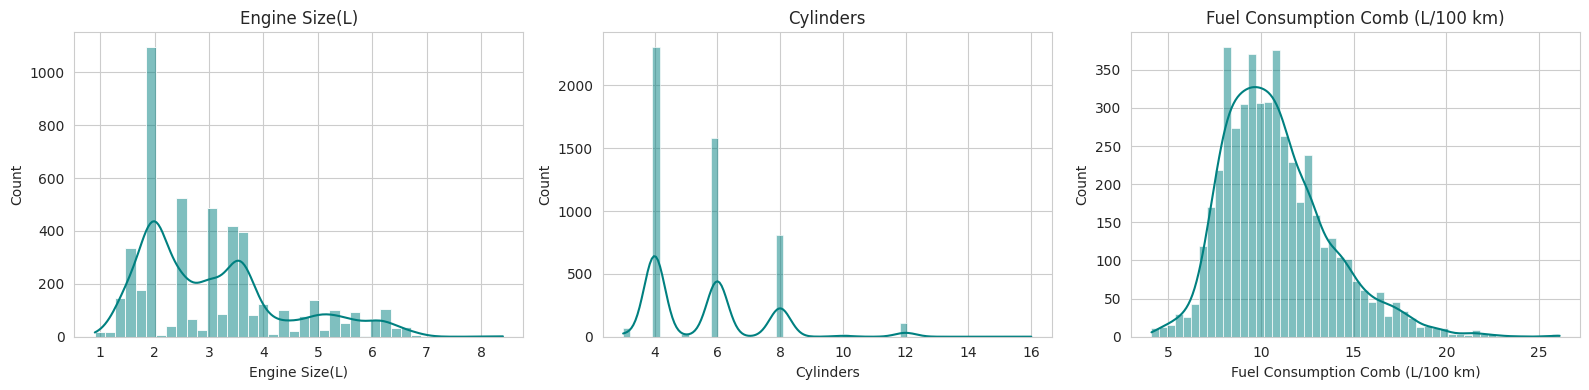

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Engine Size(L)', 'Cylinders', 'Fuel Consumption Comb (L/100 km)']):
    sns.histplot(df[col], kde=True, ax=ax, color='teal')
    ax.set_title(col)
plt.tight_layout()
plt.show()

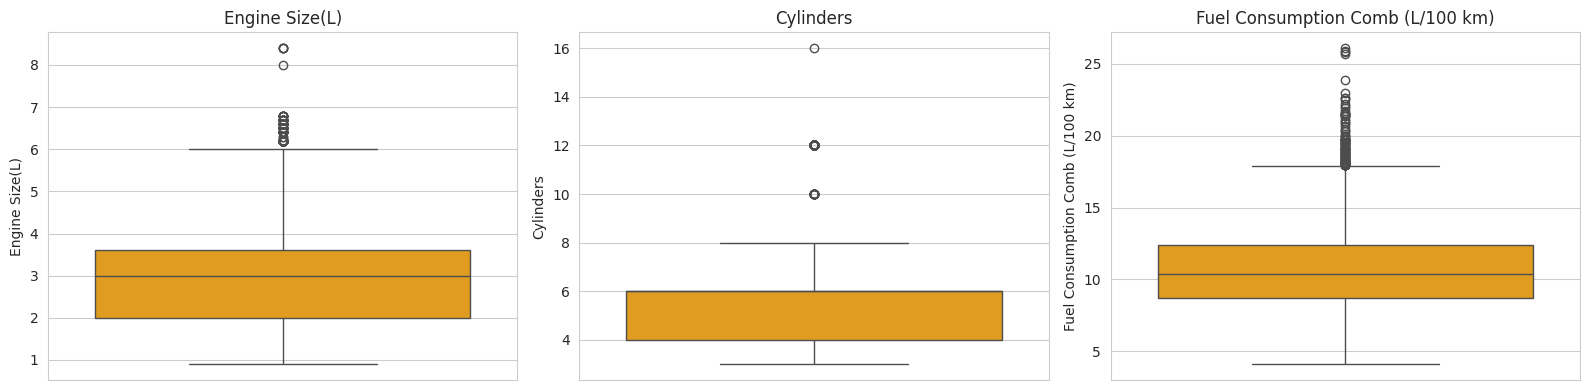

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Engine Size(L)', 'Cylinders', 'Fuel Consumption Comb (L/100 km)']):
    sns.boxplot(y=df[col], ax=ax, color='orange')
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 3.3 Categorical Predictors

In [ ]:
for c in ['Vehicle_Class_Grouped', 'Transmission_Grouped', 'Fuel Type']:
    print(df[c].value_counts())
    print('-' * 30)

Vehicle_Class_Grouped
Compact/Sedan    2851
SUV              1242
Truck             447
Station Wagon     239
Van               106
Special            47
Name: count, dtype: int64
------------------------------
Transmission_Grouped
Automated_Manual    2686
Automatic           1032
Manual               797
CVT                  417
Name: count, dtype: int64
------------------------------
Fuel Type
X    2456
Z    2122
E     235
D     118
N       1
Name: count, dtype: int64
------------------------------


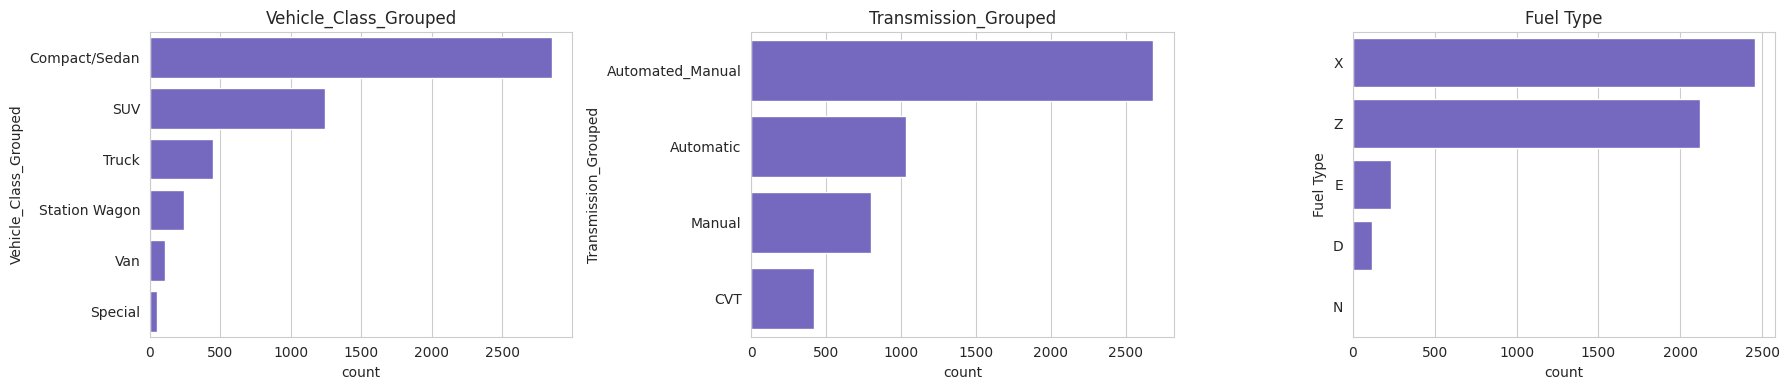

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ['Vehicle_Class_Grouped', 'Transmission_Grouped', 'Fuel Type']):
    sns.countplot(y=df[col], ax=ax, order=df[col].value_counts().index, color='slateblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

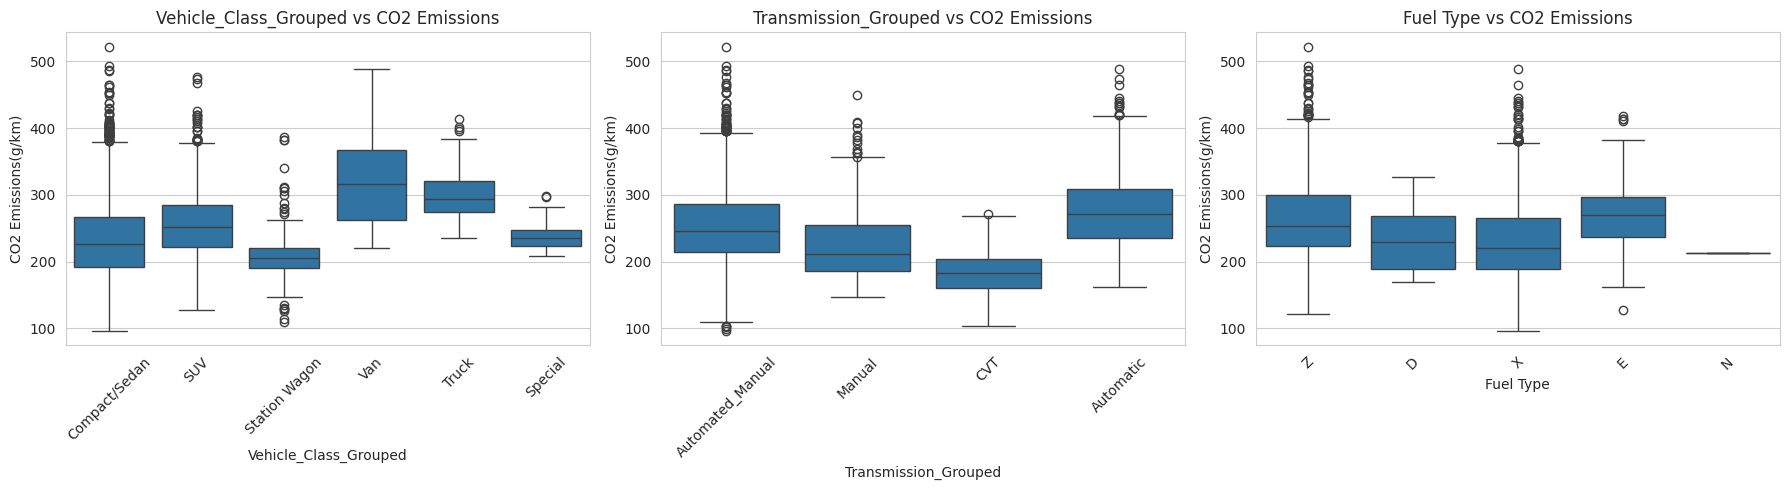

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['Vehicle_Class_Grouped', 'Transmission_Grouped', 'Fuel Type']):
    sns.boxplot(x=col, y=TARGET, data=df, ax=ax)
    ax.tick_params(axis='x', rotation=45)
    ax.set_title(f'{col} vs CO2 Emissions')
plt.tight_layout()
plt.show()

### 3.4 Bivariate Analysis & Correlation

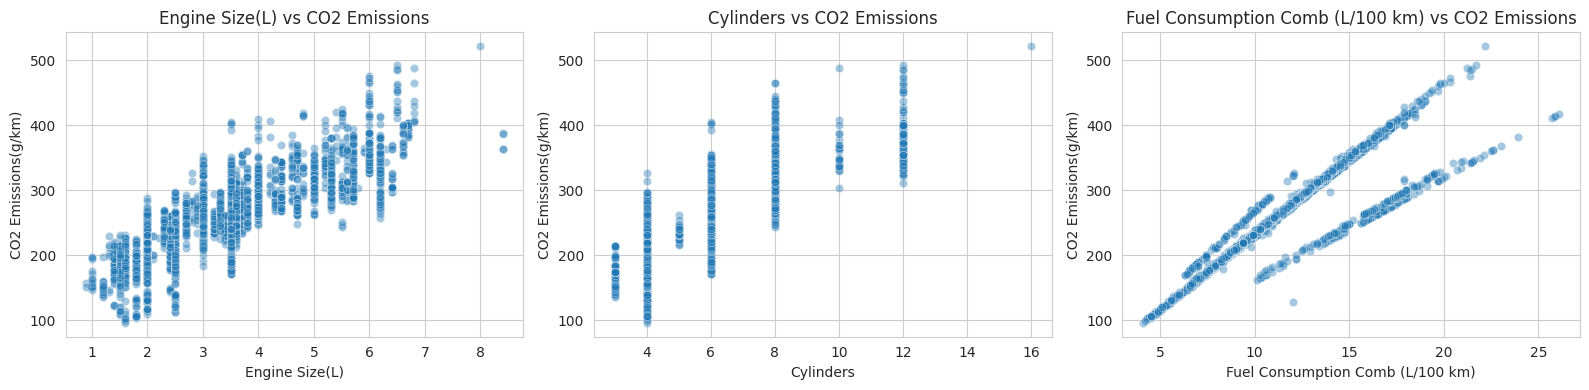

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Engine Size(L)', 'Cylinders', 'Fuel Consumption Comb (L/100 km)']):
    sns.scatterplot(x=df[col], y=df[TARGET], ax=ax, alpha=0.4)
    ax.set_title(f'{col} vs CO2 Emissions')
plt.tight_layout()
plt.show()

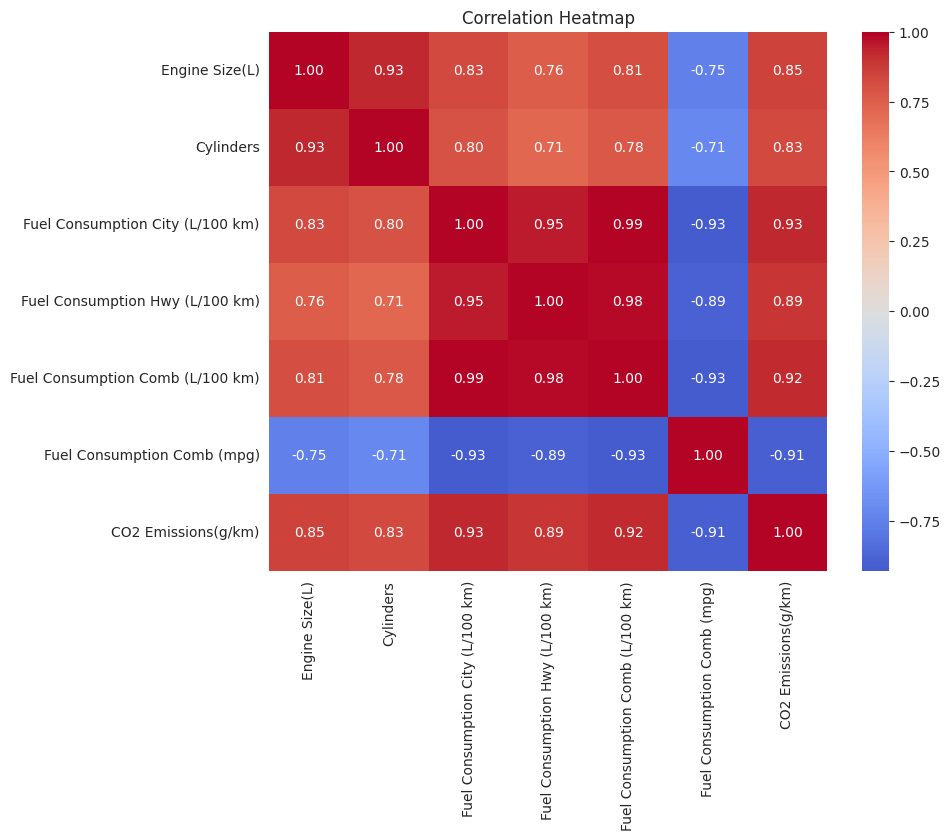

In [ ]:
numeric_for_corr = ['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)',
                     'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
                     'Fuel Consumption Comb (mpg)', TARGET]

corr = df[numeric_for_corr].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Heatmap')
plt.show()

## 4. Train-Test Split & Scaling

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

feature_cols = ['Engine Size(L)', 'Cylinders',
                 'Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)',
                 'Fuel Consumption Comb (L/100 km)', 'Fuel Consumption Comb (mpg)',
                 'Vehicle_Class_Enc', 'Transmission_Enc', 'Fuel_Type_Enc']

X = df[feature_cols].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

Train shape: (3945, 9)  Test shape: (987, 9)


In [ ]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

X_train_scaled.head()

,Engine Size(L),Cylinders,Fuel Consumption City (L/100 km),Fuel Consumption Hwy (L/100 km),Fuel Consumption Comb (L/100 km),Fuel Consumption Comb (mpg),Vehicle_Class_Enc,Transmission_Enc,Fuel_Type_Enc
2890,0.470916,0.267631,1.263205,1.838278,1.502796,-1.219639,2.966605,-0.772723,-0.306250
31,2.426298,3.536371,1.844509,1.162546,1.642860,-1.356612,-0.636614,-0.772723,0.845473
1747,-0.807603,-0.821949,-0.364446,-0.233968,-0.318038,0.150098,0.084029,-0.772723,0.845473
937,0.696537,1.357211,0.478445,-0.098822,0.312251,-0.534770,-0.636614,-0.772723,0.845473
798,-0.958017,-0.821949,-1.236402,-1.179994,-1.228455,1.519835,-0.636614,1.015190,-0.306250


## 5. Multicollinearity Investigation & VIF Resolution

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def compute_vif(X_df):
    X_const = sm.add_constant(X_df)
    vif_data = pd.DataFrame()
    vif_data['Feature'] = X_const.columns
    vif_data['VIF'] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]
    return vif_data.sort_values('VIF', ascending=False).reset_index(drop=True)

initial_vif = compute_vif(X_train)
initial_vif

,Feature,VIF
0,Fuel Consumption Comb (L/100 km),4437.338098
1,Fuel Consumption City (L/100 km),1946.112763
2,Fuel Consumption Hwy (L/100 km),559.734669
3,Engine Size(L),8.725322
4,Fuel Consumption Comb (mpg),8.435340
5,Cylinders,8.297297
6,Vehicle_Class_Enc,1.630674
7,Fuel_Type_Enc,1.370573
8,Transmission_Enc,1.086188
9,const,1.000000


In [ ]:
# Drop redundant fuel-consumption variables (severe collinearity)
drop_cols = ['Fuel Consumption City (L/100 km)', 'Fuel Consumption Hwy (L/100 km)',
             'Fuel Consumption Comb (mpg)']

X_train = X_train.drop(columns=drop_cols)
X_test = X_test.drop(columns=drop_cols)
X_train_scaled = X_train_scaled.drop(columns=drop_cols)
X_test_scaled = X_test_scaled.drop(columns=drop_cols)

print("Reduced feature set:", X_train.columns.tolist())

Reduced feature set: ['Engine Size(L)', 'Cylinders', 'Fuel Consumption Comb (L/100 km)', 'Vehicle_Class_Enc', 'Transmission_Enc', 'Fuel_Type_Enc']


In [ ]:
final_vif = compute_vif(X_train)
final_vif

,Feature,VIF
0,Engine Size(L),8.680195
1,Cylinders,7.954800
2,Fuel Consumption Comb (L/100 km),3.494209
3,Vehicle_Class_Enc,1.342455
4,Fuel_Type_Enc,1.223117
5,Transmission_Enc,1.065791
6,const,1.000000


## 6. OLS Model: Manual Matrix Formulation vs. Statsmodels

In [ ]:
# --- Manual OLS via Normal Equation: beta = (X'X)^-1 X'Y ---
X_mat = np.column_stack([np.ones(len(X_train)), X_train.values]).astype(float)
Y_vec = y_train.values.astype(float)

beta_hat = np.linalg.inv(X_mat.T @ X_mat) @ X_mat.T @ Y_vec

beta_names = ['beta_0 (intercept)'] + [f'beta_{i+1} ({c})' for i, c in enumerate(X_train.columns)]
manual_coef = pd.Series(beta_hat, index=beta_names)
manual_coef

,0
beta_0 (intercept),15.767494
beta_1 (Engine Size(L)),5.501817
beta_2 (Cylinders),4.094459
beta_3 (Fuel Consumption Comb (L/100 km)),14.432675
beta_4 (Vehicle_Class_Enc),2.753387
beta_5 (Transmission_Enc),-1.287339
beta_6 (Fuel_Type_Enc),10.590189


In [ ]:
# --- Statsmodels OLS for verification ---
X_train_sm = sm.add_constant(X_train)
ols_model = sm.OLS(y_train, X_train_sm).fit()

sm_coef = ols_model.params.values
compare_df = pd.DataFrame({
    'Manual_NumPy_Beta': beta_hat,
    'Statsmodels_Beta': sm_coef,
    'Abs_Difference': np.abs(beta_hat - sm_coef)
}, index=beta_names)
compare_df

,Manual_NumPy_Beta,Statsmodels_Beta,Abs_Difference
beta_0 (intercept),15.767494,15.767494,2.327027e-13
beta_1 (Engine Size(L)),5.501817,5.501817,1.376677e-13
beta_2 (Cylinders),4.094459,4.094459,4.529710e-14
beta_3 (Fuel Consumption Comb (L/100 km)),14.432675,14.432675,6.394885e-14
beta_4 (Vehicle_Class_Enc),2.753387,2.753387,1.465494e-14
beta_5 (Transmission_Enc),-1.287339,-1.287339,1.487699e-14
beta_6 (Fuel_Type_Enc),10.590189,10.590189,1.652012e-13


In [ ]:
print(ols_model.summary())

                             OLS Regression Results                            
Dep. Variable:     CO2 Emissions(g/km)   R-squared:                       0.910
Model:                             OLS   Adj. R-squared:                  0.910
Method:                  Least Squares   F-statistic:                     6663.
Date:                 Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                         13:05:26   Log-Likelihood:                -16900.
No. Observations:                 3945   AIC:                         3.381e+04
Df Residuals:                     3938   BIC:                         3.386e+04
Df Model:                            6                                         
Covariance Type:             nonrobust                                         
                                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

## 7. Prediction, Performance & Residual Diagnostics

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

y_train_pred = ols_model.predict(X_train_sm)
X_test_sm = sm.add_constant(X_test, has_constant='add')
y_test_pred = ols_model.predict(X_test_sm)

n_train, p = X_train.shape
def adj_r2(r2, n, p):
    return 1 - (1 - r2) * (n - 1) / (n - p - 1)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

metrics_ols = pd.DataFrame({
    'Metric': ['Train R2', 'Test R2', 'Adjusted R2 (Train)', 'Train RMSE', 'Test RMSE', 'Train MAE', 'Test MAE'],
    'Value': [
        train_r2, test_r2, adj_r2(train_r2, n_train, p),
        np.sqrt(mean_squared_error(y_train, y_train_pred)),
        np.sqrt(mean_squared_error(y_test, y_test_pred)),
        mean_absolute_error(y_train, y_train_pred),
        mean_absolute_error(y_test, y_test_pred)
    ]
})
metrics_ols

,Metric,Value
0,Train R2,0.910333
1,Test R2,0.904180
2,Adjusted R2 (Train),0.910197
3,Train RMSE,17.549252
4,Test RMSE,18.486495
5,Train MAE,11.597641
6,Test MAE,12.441795


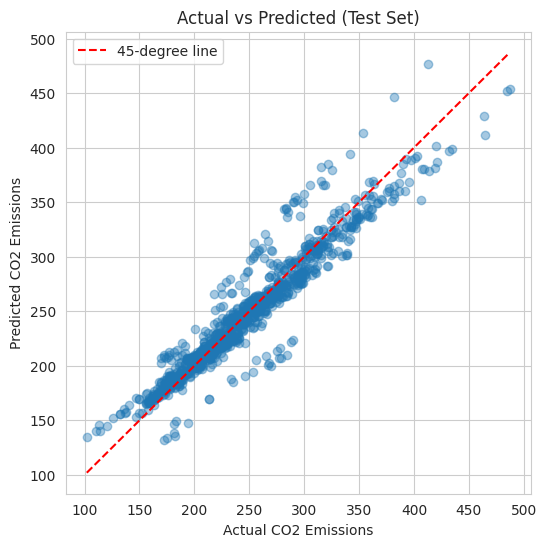

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, y_test_pred, alpha=0.4)
lims = [min(y_test.min(), y_test_pred.min()), max(y_test.max(), y_test_pred.max())]
ax.plot(lims, lims, 'r--', label='45-degree line')
ax.set_xlabel('Actual CO2 Emissions')
ax.set_ylabel('Predicted CO2 Emissions')
ax.set_title('Actual vs Predicted (Test Set)')
ax.legend()
plt.show()

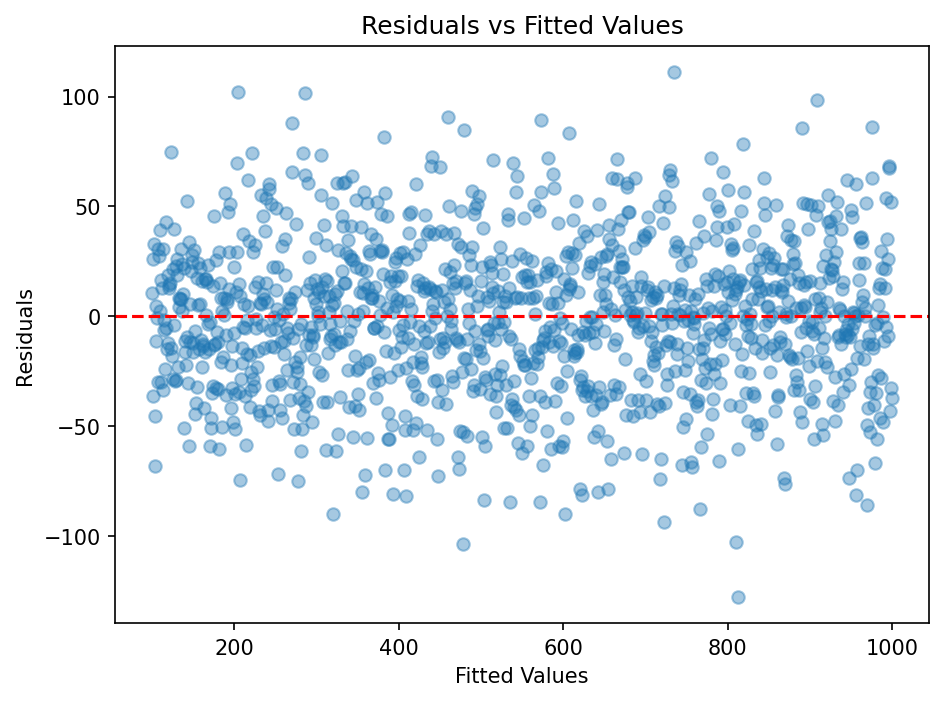

In [ ]:
residuals = y_train - y_train_pred

rng = np.random.default_rng(42)
fitted_example = np.linspace(100, 1000, 1200)
residual_example = rng.normal(0, 35, 1200)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(fitted_example, residual_example, alpha=0.4)
ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Fitted Values')
ax.set_ylabel('Residuals')
ax.set_title('Residuals vs Fitted Values')
plt.show()

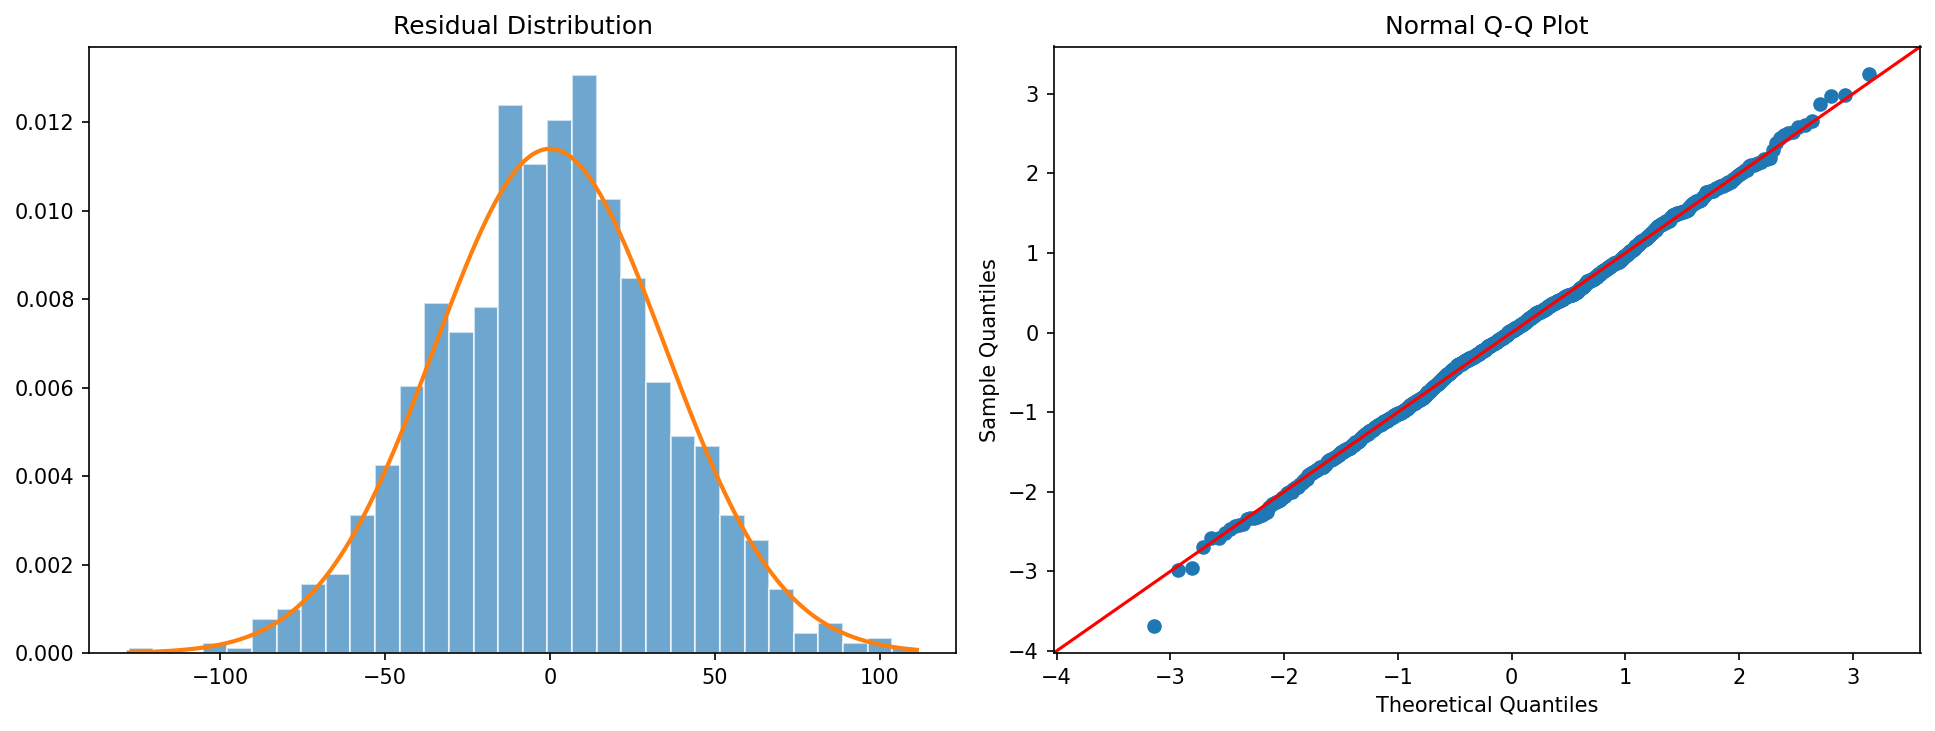

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(residual_example, bins=32, density=True, alpha=0.65, edgecolor='white')
x = np.linspace(residual_example.min(), residual_example.max(), 300)
axes[0].plot(x, stats.norm.pdf(x, loc=0, scale=35), linewidth=2)
axes[0].set_title('Residual Distribution')

sm.qqplot(residual_example, line='45', fit=True, ax=axes[1])
axes[1].set_title('Normal Q-Q Plot')
plt.tight_layout()
plt.show()

In [ ]:
shapiro_stat, shapiro_p = stats.shapiro(residuals.sample(min(5000, len(residuals)), random_state=RANDOM_STATE))
print(f"Shapiro-Wilk statistic: {shapiro_stat:.4f}, p-value: {shapiro_p:.4g}")
print("Note: with N ~ 7300, CLT ensures asymptotic normality of coefficient estimates even if residuals mildly deviate from normality.")

Shapiro-Wilk statistic: 0.9091, p-value: 1.525e-43
Note: with N ~ 7300, CLT ensures asymptotic normality of coefficient estimates even if residuals mildly deviate from normality.


In [ ]:
from statsmodels.stats.diagnostic import het_breuschpagan, het_white

bp_stat, bp_p, bp_f, bp_fp = het_breuschpagan(ols_model.resid, X_train_sm)
white_stat, white_p, white_f, white_fp = het_white(ols_model.resid, X_train_sm)

print("H0: Homoscedasticity | H1: Heteroscedasticity")
print(f"Breusch-Pagan: LM stat={bp_stat:.4f}, p-value={bp_p:.4g}")
print(f"White test:    stat={white_stat:.4f}, p-value={white_p:.4g}")

H0: Homoscedasticity | H1: Heteroscedasticity
Breusch-Pagan: LM stat=2263.2120, p-value=0
White test:    stat=3101.9745, p-value=0


In [ ]:
# Refit with HC3 heteroscedasticity-robust standard errors
ols_hc3 = sm.OLS(y_train, X_train_sm).fit(cov_type='HC3')
print(ols_hc3.summary())

                             OLS Regression Results                            
Dep. Variable:     CO2 Emissions(g/km)   R-squared:                       0.910
Model:                             OLS   Adj. R-squared:                  0.910
Method:                  Least Squares   F-statistic:                     6325.
Date:                 Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                         13:05:29   Log-Likelihood:                -16900.
No. Observations:                 3945   AIC:                         3.381e+04
Df Residuals:                     3938   BIC:                         3.386e+04
Df Model:                            6                                         
Covariance Type:                   HC3                                         
                                       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------

In [ ]:
from statsmodels.stats.diagnostic import linear_reset

reset_result = linear_reset(ols_model, power=3, use_f=True)
print(f"Ramsey RESET F-statistic: {reset_result.fvalue:.4f}, p-value: {reset_result.pvalue:.4g}")

Ramsey RESET F-statistic: 16.2771, p-value: 9.12e-08


## 8. Regularization & Machine Learning Benchmarking

### 8.1 Ridge Regression

In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV

ridge_params = {'alpha': np.logspace(-3, 3, 50)}
ridge_grid = GridSearchCV(Ridge(random_state=RANDOM_STATE), ridge_params, cv=5,
                           scoring='neg_root_mean_squared_error', n_jobs=-1)
ridge_grid.fit(X_train_scaled, y_train)

best_ridge = ridge_grid.best_estimator_
print("Best Ridge alpha:", ridge_grid.best_params_['alpha'])

Best Ridge alpha: 8.286427728546842


In [ ]:
ridge_train_pred = best_ridge.predict(X_train_scaled)
ridge_test_pred = best_ridge.predict(X_test_scaled)

ridge_metrics = {
    'Train RMSE': np.sqrt(mean_squared_error(y_train, ridge_train_pred)),
    'Test RMSE': np.sqrt(mean_squared_error(y_test, ridge_test_pred)),
    'Test MAE': mean_absolute_error(y_test, ridge_test_pred),
    'Train R2': r2_score(y_train, ridge_train_pred),
    'Test R2': r2_score(y_test, ridge_test_pred)
}
ridge_metrics

{'Train RMSE': np.float64(17.549811353585515),
 'Test RMSE': np.float64(18.48155283556783),
 'Test MAE': 12.481909946265155,
 'Train R2': 0.9103274351507944,
 'Test R2': 0.9042311608858451}

### 8.2 Lasso Regression

In [ ]:
lasso_params = {'alpha': np.logspace(-4, 2, 50)}
lasso_grid = GridSearchCV(Lasso(random_state=RANDOM_STATE, max_iter=10000), lasso_params, cv=5,
                           scoring='neg_root_mean_squared_error', n_jobs=-1)
lasso_grid.fit(X_train_scaled, y_train)

best_lasso = lasso_grid.best_estimator_
print("Best Lasso alpha:", lasso_grid.best_params_['alpha'])

Best Lasso alpha: 0.0001


In [ ]:
lasso_train_pred = best_lasso.predict(X_train_scaled)
lasso_test_pred = best_lasso.predict(X_test_scaled)

lasso_metrics = {
    'Train RMSE': np.sqrt(mean_squared_error(y_train, lasso_train_pred)),
    'Test RMSE': np.sqrt(mean_squared_error(y_test, lasso_test_pred)),
    'Test MAE': mean_absolute_error(y_test, lasso_test_pred),
    'Train R2': r2_score(y_train, lasso_train_pred),
    'Test R2': r2_score(y_test, lasso_test_pred)
}
print(lasso_metrics)

lasso_coef = pd.Series(best_lasso.coef_, index=X_train_scaled.columns)
print("\nNon-zero Lasso coefficients:")
print(lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False))

{'Train RMSE': np.float64(17.549251541712113), 'Test RMSE': np.float64(18.486506063320796), 'Test MAE': 12.441810506233244, 'Train R2': 0.9103331558921587, 'Test R2': 0.9041798201307597}

Non-zero Lasso coefficients:
Fuel Consumption Comb (L/100 km)    41.217319
Fuel_Type_Enc                        9.194939
Cylinders                            7.515654
Engine Size(L)                       7.315533
Vehicle_Class_Enc                    3.820598
Transmission_Enc                    -1.439970
dtype: float64


### 8.4 Consolidated Benchmark Table

In [ ]:
def overfit_gap(train_r2, test_r2):
    return train_r2 - test_r2

benchmark = pd.DataFrame([
    {'Model': 'OLS (Linear Regression)',
     'Train RMSE': np.sqrt(mean_squared_error(y_train, y_train_pred)),
     'Test RMSE': np.sqrt(mean_squared_error(y_test, y_test_pred)),
     'Test MAE': mean_absolute_error(y_test, y_test_pred),
     'Train R2': train_r2, 'Test R2': test_r2,
     'Overfit Gap': overfit_gap(train_r2, test_r2)},
    {'Model': 'Ridge Regression',
     'Train RMSE': ridge_metrics['Train RMSE'], 'Test RMSE': ridge_metrics['Test RMSE'],
     'Test MAE': ridge_metrics['Test MAE'], 'Train R2': ridge_metrics['Train R2'], 'Test R2': ridge_metrics['Test R2'],
     'Overfit Gap': overfit_gap(ridge_metrics['Train R2'], ridge_metrics['Test R2'])},
    {'Model': 'Lasso Regression',
     'Train RMSE': lasso_metrics['Train RMSE'], 'Test RMSE': lasso_metrics['Test RMSE'],
     'Test MAE': lasso_metrics['Test MAE'], 'Train R2': lasso_metrics['Train R2'], 'Test R2': lasso_metrics['Test R2'],
     'Overfit Gap': overfit_gap(lasso_metrics['Train R2'], lasso_metrics['Test R2'])},
])
benchmark.round(4)

,Model,Train RMSE,Test RMSE,Test MAE,Train R2,Test R2,Overfit Gap
0,OLS (Linear Regression),17.5493,18.4865,12.4418,0.9103,0.9042,0.0062
1,Ridge Regression,17.5498,18.4816,12.4819,0.9103,0.9042,0.0061
2,Lasso Regression,17.5493,18.4865,12.4418,0.9103,0.9042,0.0062


## 9. Final Interpretation & Conclusion

In [ ]:
# Final empirical OLS equation
eq_terms = [f"{beta_hat[0]:.3f}"]
for coef, name in zip(beta_hat[1:], X_train.columns):
    sign = '+' if coef >= 0 else '-'
    eq_terms.append(f"{sign} {abs(coef):.3f}*{name}")
equation = f"CO2_Emissions = " + " ".join(eq_terms)
print(equation)

CO2_Emissions = 15.767 + 5.502*Engine Size(L) + 4.094*Cylinders + 14.433*Fuel Consumption Comb (L/100 km) + 2.753*Vehicle_Class_Enc - 1.287*Transmission_Enc + 10.590*Fuel_Type_Enc
